In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view


TypeError: Image data of dtype object cannot be converted to float

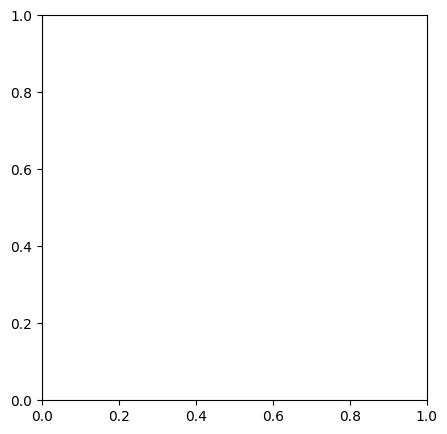

In [6]:
image = cv2.imread("../data/shoes.png", cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=(6, 5))
plt.imshow(image, cmap="gray")
plt.title("Original Grayscale Image", fontsize=14)
plt.axis("off")
plt.show()

print("Image Dimensions:", image.shape)


In [5]:
# Sobel related functions


def _pascal_row(n: int) -> np.ndarray:
    """Return row n of Pascal's triangle (binomial coefficients), length n+1."""
    row = [1]
    for k in range(n):
        row.append(row[-1] * (n - k) // (k + 1))
    return np.array(row, dtype=np.float64)


def _sobel_smoothing_vector(size: int) -> np.ndarray:
    """1D binomial smoothing vector of given odd length, e.g. size=3 -> [1,2,1]."""
    return _pascal_row(size - 1)


def _sobel_derivative_vector(size: int) -> np.ndarray:
    """1D antisymmetric derivative vector of given odd length, e.g. size=3 -> [-1,0,1]."""
    smaller = _pascal_row(size - 2)          # length size-1
    return -np.convolve(smaller, [1, -1])    # length size


def compute_sobel_kernel_x(size: int) -> np.ndarray:
    """Sobel kernel for gradients in the x-direction (horizontal edges detector)."""
    if size < 3 or size % 2 == 0:
        raise ValueError("size must be an odd integer >= 3")
    s = _sobel_smoothing_vector(size)   # smooths along y
    d = _sobel_derivative_vector(size)  # differentiates along x
    return np.outer(s, d)


def compute_sobel_kernel_y(size: int) -> np.ndarray:
    """Sobel kernel for gradients in the y-direction (vertical edges detector)."""
    if size < 3 or size % 2 == 0:
        raise ValueError("size must be an odd integer >= 3")
    s = _sobel_smoothing_vector(size)   # smooths along x
    d = _sobel_derivative_vector(size)  # differentiates along y
    return np.outer(d, s)

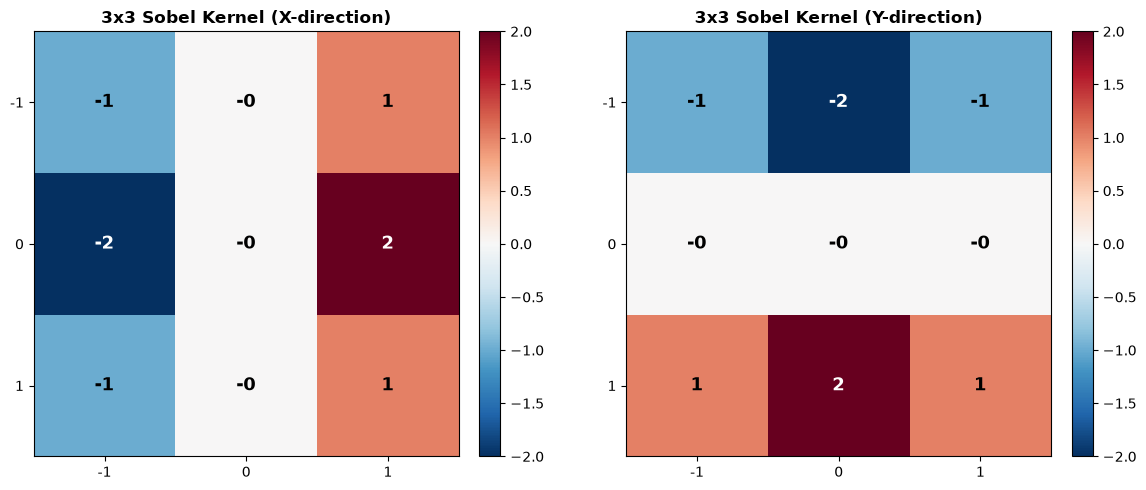

3x3 Sobel X Matrix:
[[-1. -0.  1.]
 [-2. -0.  2.]
 [-1. -0.  1.]]
3x3 Sobel Y Matrix:
[[-1. -2. -1.]
 [-0. -0. -0.]
 [ 1.  2.  1.]]


In [7]:
k3_x = compute_sobel_kernel_x(3)
k3_y = compute_sobel_kernel_y(3)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(k3_x, cmap="RdBu_r", vmin=-2, vmax=2)
axes[0].set_title("3x3 Sobel Kernel (X-direction)", fontsize=12, fontweight="bold")
for i in range(3):
    for j in range(3):
        val = k3_x[i, j]
        axes[0].text(j, i, f"{val:.0f}", ha="center", va="center", color="white" if abs(val) > 1 else "black", fontsize=13, fontweight="bold")
axes[0].set_xticks(range(3))
axes[0].set_yticks(range(3))
axes[0].set_xticklabels([-1, 0, 1])
axes[0].set_yticklabels([-1, 0, 1])
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(k3_y, cmap="RdBu_r", vmin=-2, vmax=2)
axes[1].set_title("3x3 Sobel Kernel (Y-direction)", fontsize=12, fontweight="bold")
for i in range(3):
    for j in range(3):
        val = k3_y[i, j]
        axes[1].text(j, i, f"{val:.0f}", ha="center", va="center", color="white" if abs(val) > 1 else "black", fontsize=13, fontweight="bold")
axes[1].set_xticks(range(3))
axes[1].set_yticks(range(3))
axes[1].set_xticklabels([-1, 0, 1])
axes[1].set_yticklabels([-1, 0, 1])
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

print("3x3 Sobel X Matrix:")
print(np.round(k3_x, 4))
print("3x3 Sobel Y Matrix:")
print(np.round(k3_y, 4))

In [14]:
def apply_sobel_filter(img: np.ndarray, kernel_size: int = 3, stride: int = 1) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    kx = compute_sobel_kernel_x(kernel_size)
    ky = compute_sobel_kernel_y(kernel_size)
    pad_amt = kernel_size // 2
    padded = np.pad(img, pad_amt, mode="reflect")
    windows = sliding_window_view(padded, (kernel_size, kernel_size))[::stride, ::stride]

    gx = (windows * kx).sum(axis=(-1, -2))
    gy = (windows * ky).sum(axis=(-1, -2))
    magnitude = np.hypot(gx, gy)

    edges_x = np.clip(np.abs(gx), 0, 255).astype(np.uint8)
    edges_y = np.clip(np.abs(gy), 0, 255).astype(np.uint8)
    edges_combined = np.clip(magnitude, 0, 255).astype(np.uint8)
    return edges_x, edges_y, edges_combined

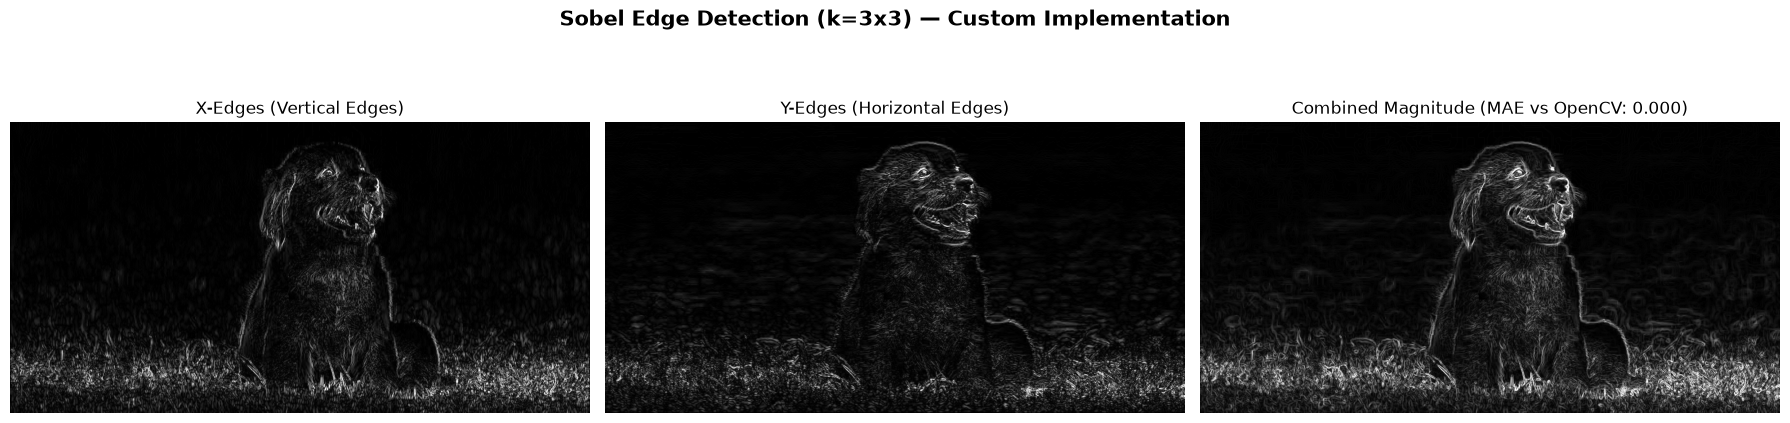

In [15]:
k_size = 3

cv_gx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=k_size)
cv_gy = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=k_size)
cv_edges_x = np.clip(np.abs(cv_gx), 0, 255).astype(np.uint8)
cv_edges_y = np.clip(np.abs(cv_gy), 0, 255).astype(np.uint8)
cv_combined = np.clip(np.hypot(cv_gx, cv_gy), 0, 255).astype(np.uint8)

custom_edges_x, custom_edges_y, custom_combined = apply_sobel_filter(image, kernel_size=k_size)

diff_map = np.abs(cv_combined.astype(np.int32) - custom_combined.astype(np.int32))
mean_abs_diff = np.mean(diff_map)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle(f"Sobel Edge Detection (k={k_size}x{k_size}) — Custom Implementation", fontsize=15, fontweight="bold")

axes[0].imshow(custom_edges_x, cmap="gray")
axes[0].set_title("X-Edges (Vertical Edges)", fontsize=12)
axes[0].axis("off")

axes[1].imshow(custom_edges_y, cmap="gray")
axes[1].set_title("Y-Edges (Horizontal Edges)", fontsize=12)
axes[1].axis("off")

axes[2].imshow(custom_combined, cmap="gray")
axes[2].set_title(f"Combined Magnitude (MAE vs OpenCV: {mean_abs_diff:.3f})", fontsize=12)
axes[2].axis("off")

plt.tight_layout()
plt.show()